# Import Libraries

In [46]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error


---

# **Ερώτημα 1**

In [47]:
df = pd.read_csv('diabetes.csv')
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [48]:
df.describe().loc[["mean", "std", "min", "max"]]

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


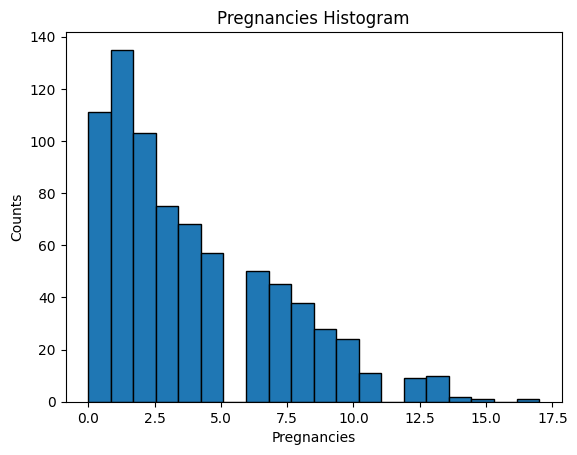

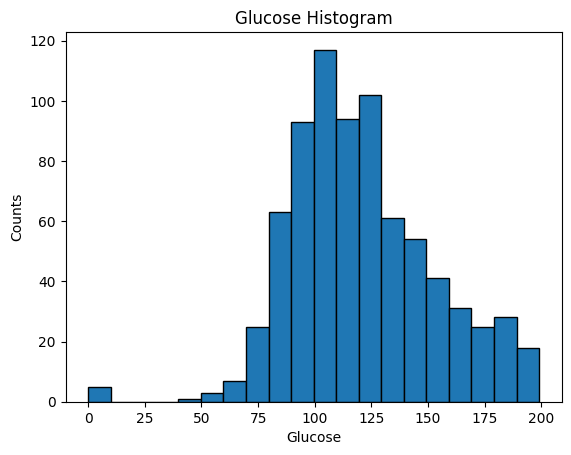

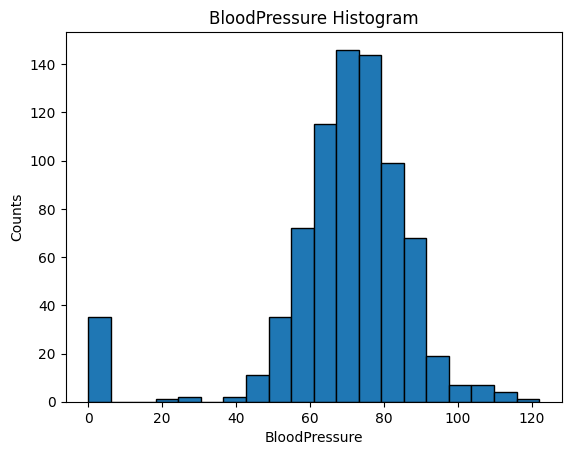

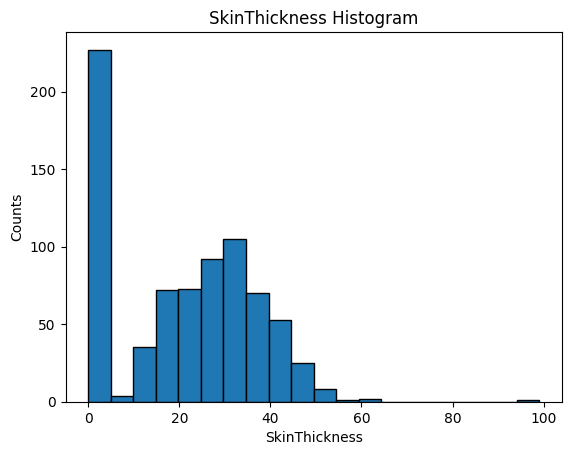

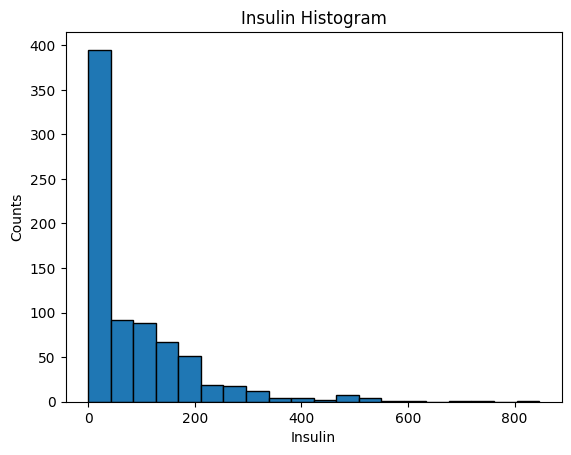

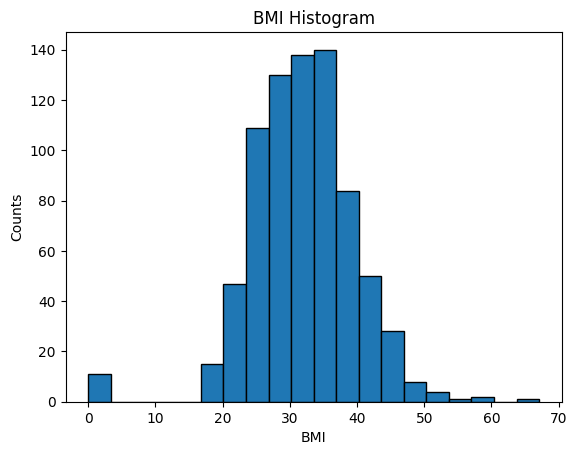

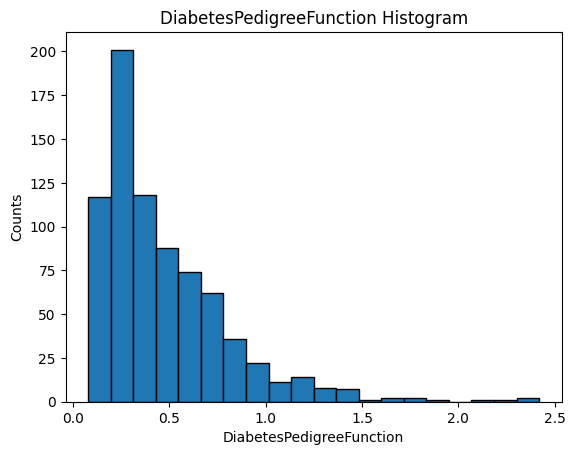

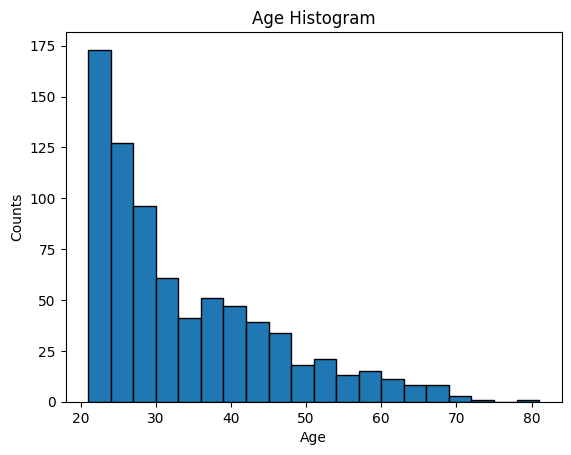

In [49]:

features = df.columns.drop("Outcome")

for column in features:
  df[column].hist(bins=20, edgecolor='black')
  plt.title(f"{column} Histogram")
  plt.xlabel(column)
  plt.ylabel('Counts')
  plt.grid(False)
  plt.show()


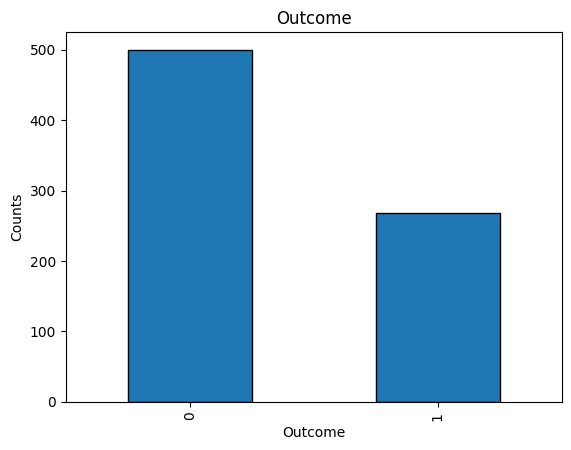

In [50]:
df["Outcome"].value_counts().plot(kind="bar", edgecolor="black")
plt.title("Outcome")
plt.xlabel("Outcome")
plt.ylabel("Counts")
plt.show()

---


# **Ερώτημα 2**


In [51]:
input_df = df.drop(columns=['Outcome'])
targets_df = df['Outcome']

x = input_df.to_numpy()
y = targets_df.to_numpy()
x.shape, y.shape

((768, 8), (768,))

In [52]:
seed = 0
test_size = 0.3

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=test_size, random_state=seed)
x_train.shape, y_train.shape, x_test.shape, y_test.shape

((537, 8), (537,), (231, 8), (231,))

---
# **Ερώτημα 3**

In [53]:
model = LogisticRegression(max_iter=5000, random_state=seed)

In [54]:
model.fit(x_train, y_train)

LogisticRegression(max_iter=5000, random_state=0)

In [55]:
y_train_pred = model.predict(x_train)
y_train_pred
y_test_pred = model.predict(x_test)
y_test_pred

array([1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1,
       1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1,
       1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0])

In [56]:
print("Train accuracy:", accuracy_score(y_train, model.predict(x_train)))
print("Test accuracy:", accuracy_score(y_test, model.predict(x_test)))

Train accuracy: 0.7653631284916201
Test accuracy: 0.7792207792207793


Παρατηρούμε ότι η ακρίβεια στο test set είναι  υψηλότερη από ότι στο train set. Αυτό δείχνει ότι δεν υπάρχει overfitting και ότι το μοντέλο έχει μάθει από τα δεδομένα εκπαίδευσης παρουσιάζοντας παρόμοια απόδοση και σε νέα δεδομένα.


---
# **Ερώτημα 4**

In [57]:
df.groupby('Outcome')['Glucose'].mean()

,Glucose
Outcome,
0,109.980000
1,141.257463


Παρατηρούμε ότι οι ασθενείς με διαβήτη έχουν υψηλότερα επίπεδα γλυκόζης σε σύγκριση με τους ασθενείς χωρίς διαβήτη.

---
# **Ερώτημα 5**

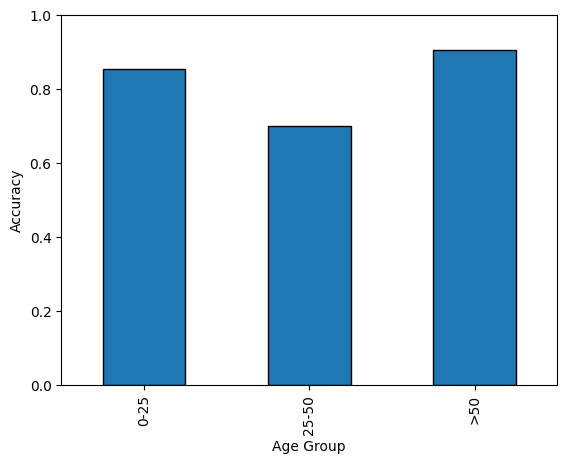

In [58]:
test_df = pd.DataFrame(x_test, columns=input_df.columns)
test_df['Outcome'] = y_test
test_df['Prediction'] = model.predict(x_test)
test_df['Correct'] = test_df['Outcome'] == test_df['Prediction']
test_df['AgeGroup'] = pd.cut(test_df['Age'], bins=[0, 25, 50, float('inf')],
                             labels=['0-25', '25-50', '>50'])

accuracies = test_df.groupby('AgeGroup', observed=False)['Correct'].mean()

accuracies.plot(kind='bar', edgecolor='black')
plt.ylabel('Accuracy')
plt.xlabel('Age Group')
plt.ylim(0, 1)
plt.show()

---
# **Ερώτημα 6**

Είναι χειρότερο ο ταξινομητής να προβλέπει ότι ένας ασθενής δεν έχει διαβήτη ενώ στην πραγματικότητα έχει (False Negative).

---
# **Μέρος 2 – Γραμμική Παλινδρόμηση**

---
# **Ερώτημα 1**

In [59]:
df = pd.read_csv('diabetes.csv')

x = df[['Pregnancies', 'BloodPressure', 'BMI', 'Age']].to_numpy()
y = df['Glucose'].to_numpy()

x_train, x_val, y_train, y_val = train_test_split(
    x, y, test_size=0.3, random_state=0
)

---
# **Ερώτημα 2**

In [60]:
model = LinearRegression()
model.fit(x_train, y_train)

y_pred = model.predict(x_val)

print("MAE:", mean_absolute_error(y_val, y_pred))
print("MSE:", mean_squared_error(y_val, y_pred))

MAE: 23.599990462075155
MSE: 929.8883492746899


Παρατηρούμε οτι η μετρική Mean Absolute Error είναι καταλληλότερη καθώς μας δείχνει οτι οι προβλέψεις απέχουνε περίπου 23.59 μονάδες απο τις πραγματικές τιμές γλυκόζης.

---
# **Ερώτημα 3**

In [61]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)

model = LinearRegression()
model.fit(x_train_scaled, y_train)

LinearRegression()

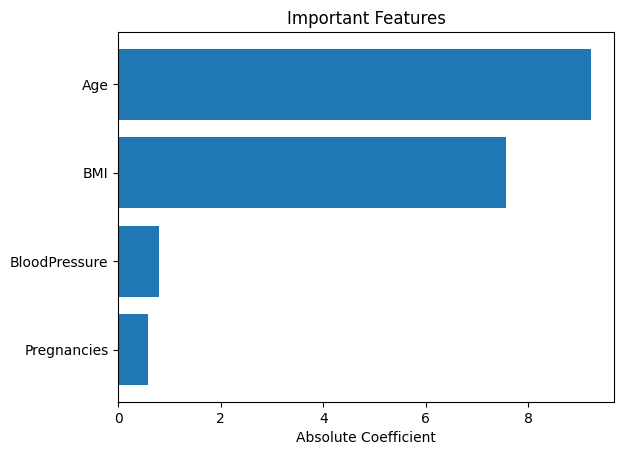

In [62]:
coeffs = model.coef_
importance_weights = np.abs(coeffs)
plt.barh(['Pregnancies', 'BloodPressure', 'BMI', 'Age'], importance_weights)
plt.title('Important Features')
plt.xlabel('Absolute Coefficient')
plt.show()

Παρατηρούμε οτι μετά την κανονικοποίηση η σημαντικότερη μεταβλητή για την πρόβλεψη της γλυκόζης είναι η ηλίκια.